# 04 — Pass Depth & Accuracy: Brady vs. Mahomes

**Research question:** How did Brady and Mahomes distribute their pass attempts across target depths, and how successfully did they execute throws relative to model expectations?

**Predefined comparison windows (within the first 131 regular-season starts):**

- **Tom Brady:** 2006–2010; **53 starts**, including only one game in 2008 and four in 2010.
- **Patrick Mahomes:** 2018–2021; **62 starts**, ending before Tyreek Hill's departure.

This is **not** a comparison of two complete, equal-length career periods or a causal evaluation of quarterback skill. All values use previously validated official-style pass attempts; sacks, scrambles, and two-point attempts are not target-depth throws. Results are descriptive and not adjusted for every aspect of offensive context.

## 1. Data loading and integrity checks

Run `python3 scripts/build_pass_depth_cpoe.py` from the repository root first. It uses the same pass-attempt selection rules as the audited passing statistics pipeline and checks reconciliation against `qb_game_stats.parquet`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path("../data/processed")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

summary = pd.DataFrame(pl.read_parquet(DATA / "qb_pass_depth_summary.parquet").to_dicts())
seasons = pd.DataFrame(pl.read_parquet(DATA / "qb_pass_depth_by_season.parquet").to_dicts())
games = pd.DataFrame(pl.read_parquet(DATA / "qb_pass_depth_by_game.parquet").to_dicts())

ORDER = ["Behind LOS", "0–5", "6–10", "11–19", "20+"]
PLAYERS = ["Tom Brady", "Patrick Mahomes"]
COLORS = {"Tom Brady": "#002244", "Patrick Mahomes": "#E31837"}

assert set(summary.player_name) == set(PLAYERS)
assert summary.groupby("player_name")["attempt_share_pct"].sum().between(99.999,100.001).all()
assert (summary["modeled_attempts"] <= summary["attempts"]).all()
assert np.allclose(summary["modeled_completion_pct"] - summary["expected_completion_pct"], summary["cpoe_pp"], atol=1e-8)

counts = (games[["player_name", "game_id"]].drop_duplicates()
          .groupby("player_name").size())
assert counts["Tom Brady"] == 53 and counts["Patrick Mahomes"] == 62

pd.options.display.float_format = "{:,.2f}".format
print("Pass attempts by player:")
display(summary.groupby("player_name")[["attempts", "modeled_attempts", "epa_attempts"]].sum())
print("Starts in the comparison:")
display(counts.rename("starts"))

Pass attempts by player:


,attempts,modeled_attempts,epa_attempts
player_name,,,
Patrick Mahomes,2309,2221,2309
Tom Brady,1793,1767,1793


Starts in the comparison:


player_name
Patrick Mahomes    62
Tom Brady          53
Name: starts, dtype: int64

### Depth zones and metric definitions

| Zone | `air_yards` | Meaning |
|---|---|---|
| Behind LOS | below 0 | Throws behind the line of scrimmage |
| 0–5 | 0 to 5 | Very short throws |
| 6–10 | 6 to 10 | Short-to-intermediate throws |
| 11–19 | 11 to 19 | Intermediate throws |
| 20+ | 20 or more | Deep throws |

- **Attempt share:** zone attempts ÷ all attempts with measured air yards.
- **Completion percentage:** completed throws ÷ all throws in the depth zone.
- **QB EPA per attempt:** summed `qb_epa` ÷ zone attempts with available EPA, **not** EPA per dropback.
- **CPOE (percentage points):** `100 × mean(completion − cp)` over exactly those throws with modeled completion probability. Source `cpoe` was checked to have percentage-point units.

A `cp`-missing throw remains eligible for the first two metrics if its depth is known; it is **not** treated as having zero CPOE. For comparison of actual and expected completion, use `modeled_completion_pct`, not the completion percentage calculated from all attempts.

## 2. Exact study-window results

In [2]:
names = {
    "attempts": "Attempts",
    "attempt_share_pct": "Attempt share (%)",
    "completions": "Completions",
    "completion_pct": "Completion (%)",
    "modeled_attempts": "CP N",
    "cp_coverage_pct": "CP coverage (%)",
    "expected_completion_pct": "Expected completion (%)",
    "modeled_completion_pct": "Observed, CP sample (%)",
    "cpoe_pp": "CPOE (pp)",
    "qb_epa_per_attempt": "QB EPA / attempt",
}
view = (summary.set_index(["player_name", "depth_zone"])
        .reindex(pd.MultiIndex.from_product([PLAYERS, ORDER], names=["player_name", "depth_zone"]))
        [list(names)].rename(columns=names))
display(view.round(2))

Attempts  Attempt share (%)  Completions  \
player_name     depth_zone                                             
Tom Brady       Behind LOS       200              11.15       167.00   
                0–5              761              42.44       553.00   
                6–10             331              18.46       229.00   
                11–19            299              16.68       158.00   
                20+              202              11.27        74.00   
Patrick Mahomes Behind LOS       417              18.06       360.00   
                0–5              723              31.31       529.00   
                6–10             445              19.27       284.00   
                11–19            420              18.19       233.00   
                20+              304              13.17       122.00   

                            Completion (%)  CP N  CP coverage (%)  \
player_name     depth_zone                                          
Tom Brady       Behind LOS           83.50   193            96.50   
                0–5                  72.67   750            98.55   
                6–10                 69.18   328            99.09   
                11–19                52.84   297            99.33   
                20+                  36.63   199            98.51   
Patrick Mahomes Behind LOS           86.33   410            98.32   
                0–5                  73.17   688            95.16   
                6–10                 63.82   432            97.08   
                11–19                55.48   395            94.05   
                20+                  40.13   296            97.37   

                            Expected completion (%)  Observed, CP sample (%)  \
player_name     depth_zone                                                     
Tom Brady       Behind LOS                    80.04                    84.46   
                0–5                           68.35                    73.33   
                6–10                          61.77                    69.82   
                11–19                         53.25                    52.86   
                20+                           32.46                    36.68   
Patrick Mahomes Behind LOS                    85.21                    87.80   
                0–5                           72.30                    76.89   
                6–10                          65.84                    65.74   
                11–19                         56.44                    58.99   
                20+                           35.29                    41.22   

                            CPOE (pp)  QB EPA / attempt  
player_name     depth_zone                               
Tom Brady       Behind LOS       4.42              0.21  
                0–5              4.98              0.23  
                6–10             8.04              0.48  
                11–19           -0.39              0.41  
                20+              4.23              0.60  
Patrick Mahomes Behind LOS       2.59              0.14  
                0–5              4.59              0.24  
                6–10            -0.10              0.32  
                11–19            2.55              0.56  
                20+              5.93              0.78

## 3. Attempt share by target depth

**Question:** Which throwing depths accounted for each quarterback's passing volume?

Attempt share uses only throws with valid air yards. The upstream audit found one Mahomes 2020 throw without `air_yards`; it is excluded from the zone denominator but retained in the overall official-attempt reconciliation.

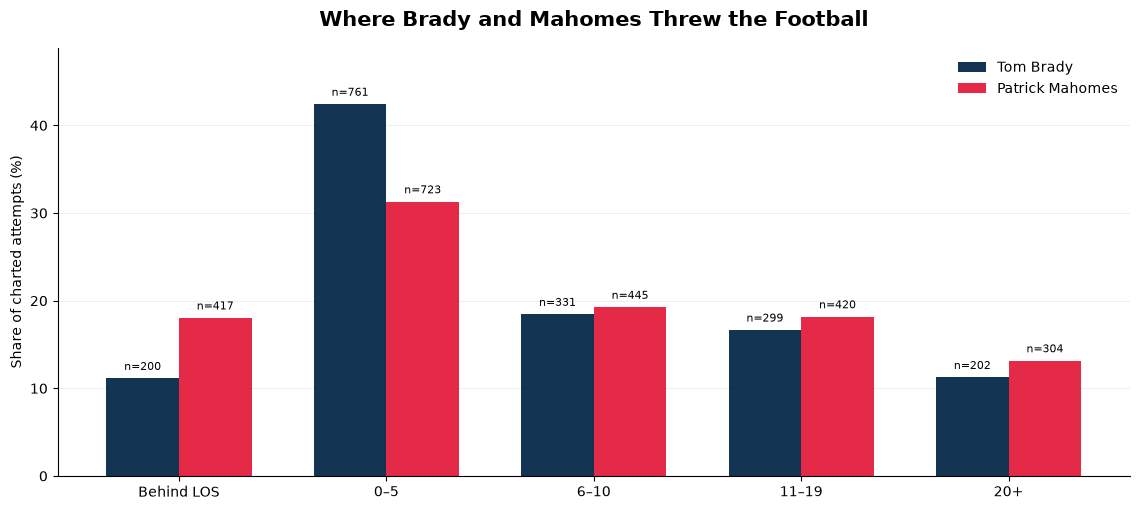

In [3]:
def grouped_bars(metric, ylabel, title, filename, display_n=False, zero_line=False):
    x = np.arange(len(ORDER))
    width = 0.35
    fig, ax = plt.subplots(figsize=(11.5, 5.2))
    for i, player in enumerate(PLAYERS):
        piece = summary[summary.player_name.eq(player)].set_index("depth_zone").reindex(ORDER)
        vals = piece[metric].to_numpy(dtype=float)
        xpos = x + (i - .5)*width
        ax.bar(xpos, vals, width=width, color=COLORS[player], label=player, alpha=.92)
        if display_n:
            for j, val in enumerate(vals):
                ax.annotate(f"n={int(piece.iloc[j]['attempts'])}",
                            (xpos[j],val),ha="center",va="bottom",fontsize=8,
                            xytext=(0,4), textcoords="offset points")
    if zero_line:
        ax.axhline(0, linewidth=1, color="#586577")
    ax.set_xticks(x, ORDER)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=15, fontweight="bold", pad=16)
    ax.legend(frameon=False, loc="upper right")
    ax.grid(axis="y", alpha=.2)
    ax.set_axisbelow(True)
    ax.spines[["top","right"]].set_visible(False)
    ax.margins(y=.15)
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=300, bbox_inches="tight")
    plt.show()

grouped_bars("attempt_share_pct", "Share of charted attempts (%)",
             "Where Brady and Mahomes Threw the Football",
             "14_pass_depth_attempt_share.png", display_n=True)

## 4. Observed completion percentage by depth

Completion rates usually decrease with depth. This comparison is *descriptive* and does not yet account for the difference in modeled throw difficulty; the next section does.

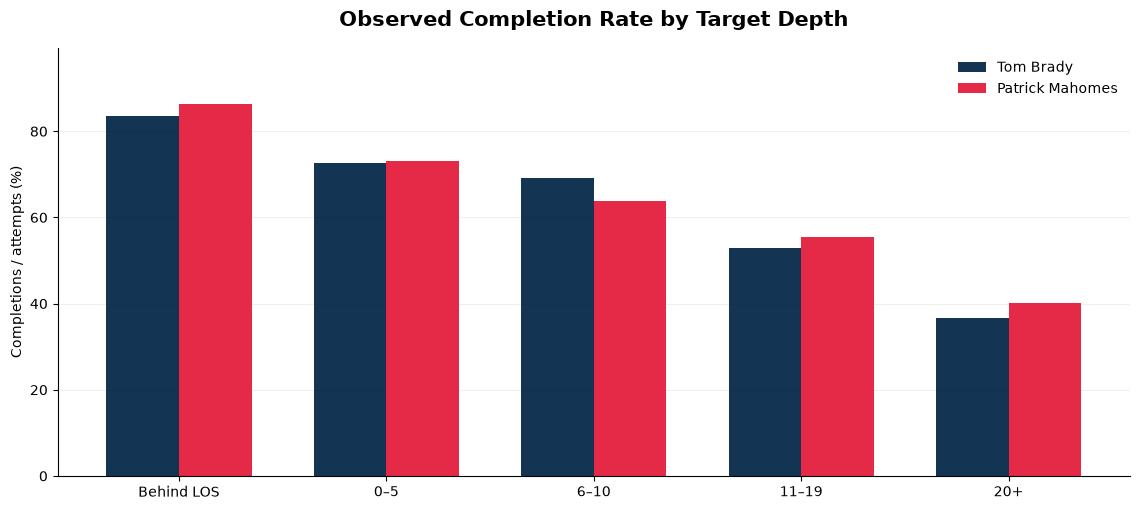

In [4]:
grouped_bars("completion_pct", "Completions / attempts (%)",
             "Observed Completion Rate by Target Depth",
             "15_pass_depth_completion_pct.png")

## 5. QB EPA per pass attempt by depth

This is **QB EPA on passes only**, divided by the number of eligible attempts in each zone. It is not equivalent to the EPA per dropback metrics in notebook 03: sacks and scrambles do not have meaningful throw depth and are not assigned to zones.

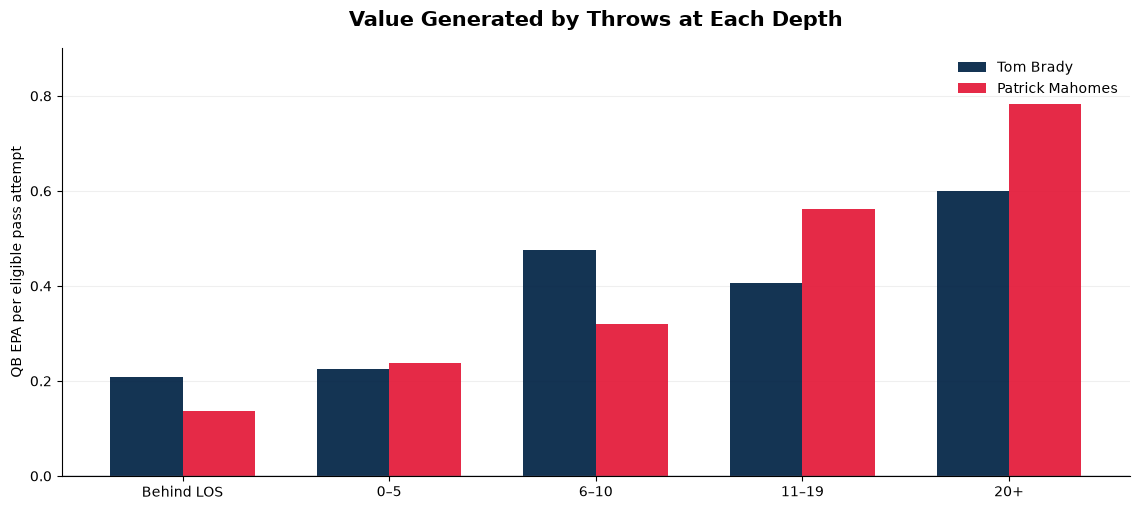

In [5]:
grouped_bars("qb_epa_per_attempt", "QB EPA per eligible pass attempt",
             "Value Generated by Throws at Each Depth",
             "16_pass_depth_qb_epa_per_attempt.png", zero_line=True)

## 6. Completion Percentage Over Expected (CPOE) — primary analysis

**Interpretation:** CPOE compares actual completion outcomes to `cp`, the nflfastR model's expected completion probability for each modeled throw. Values are expressed in **percentage points**.

A value of **+5 pp** means the observed completion percentage exceeded the model's average expectation by five percentage points *within the modeled sample*; it does not mean five percent more throws, five percent extra EPA, or proof that the quarterback alone caused the difference.

We compute exploratory uncertainty intervals by **resampling whole games**, not individual throws. This respects within-game dependence better than treating each pass as independent. These are descriptive bootstrap intervals, not causal confidence statements.

,player_name,depth_zone,modeled_attempts,cpoe_pp,ci_low,ci_high,cp_coverage_pct
0,Patrick Mahomes,Behind LOS,410,2.59,-1.13,6.05,98.32
1,Patrick Mahomes,0–5,688,4.59,1.26,8.11,95.16
2,Patrick Mahomes,6–10,432,-0.10,-4.44,3.86,97.08
3,Patrick Mahomes,11–19,395,2.55,-2.55,7.80,94.05
4,Patrick Mahomes,20+,296,5.93,-0.06,11.73,97.37
5,Tom Brady,Behind LOS,193,4.42,-0.20,8.69,96.50
6,Tom Brady,0–5,750,4.98,1.67,8.19,98.55
7,Tom Brady,6–10,328,8.04,3.42,12.52,99.09
8,Tom Brady,11–19,297,-0.39,-6.06,5.74,99.33
9,Tom Brady,20+,199,4.23,-1.71,11.12,98.51


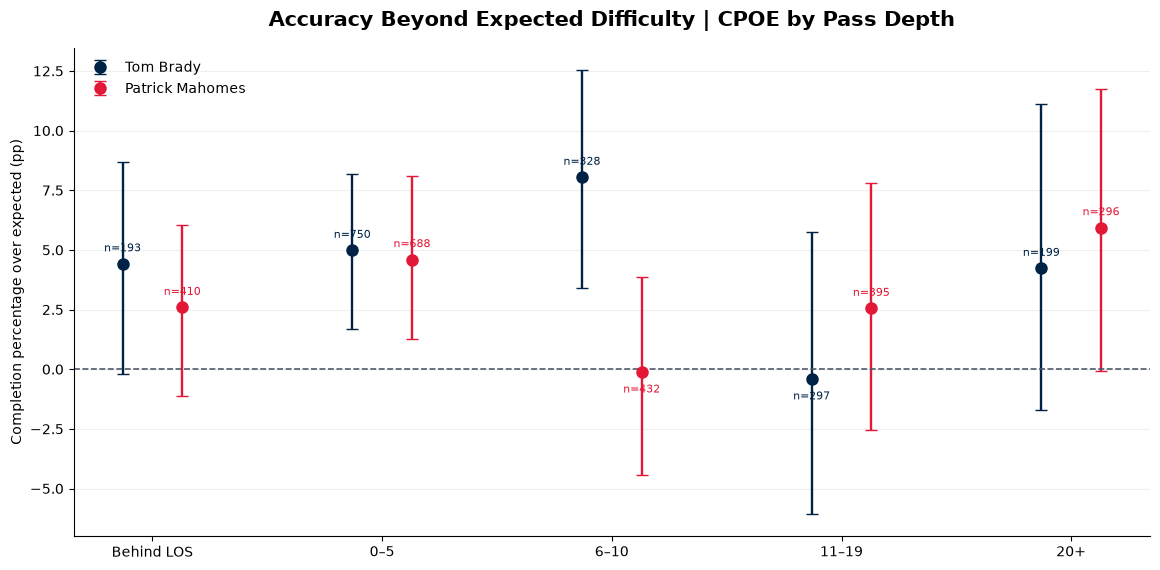

In [6]:
def game_cluster_cpoe_intervals(games_df, repetitions=3000, seed=2026):
    rng = np.random.default_rng(seed)
    rows = []
    for player in PLAYERS:
        data = games_df[games_df.player_name == player]
        ids = np.array(sorted(data.game_id.unique()))
        draws = rng.integers(0, len(ids), size=(repetitions, len(ids)))
        for zone in ORDER:
            z = data[data.depth_zone == zone].set_index("game_id")
            denominators = z.reindex(ids)["modeled_attempts"].fillna(0).to_numpy(dtype=float)
            numerators = z.reindex(ids)["sum_cpoe_pp"].fillna(0).to_numpy(dtype=float)
            sampled_n = denominators[draws].sum(axis=1)
            sampled_sum = numerators[draws].sum(axis=1)
            boot = np.divide(sampled_sum, sampled_n,
                             out=np.full(repetitions, np.nan), where=sampled_n > 0)
            valid = boot[np.isfinite(boot)]
            low, high = np.quantile(valid, [.025, .975]) if len(valid) else (np.nan, np.nan)
            rows.append({"player_name": player, "depth_zone": zone,
                         "ci_low": low, "ci_high": high, "games": len(ids)})
    return pd.DataFrame(rows)

intervals = game_cluster_cpoe_intervals(games)
results = summary.merge(intervals, on=["player_name", "depth_zone"], validate="one_to_one")

display(results[["player_name", "depth_zone", "modeled_attempts", "cpoe_pp",
                 "ci_low", "ci_high", "cp_coverage_pct"]].round(2))

fig, ax = plt.subplots(figsize=(11.7, 5.8))
x = np.arange(len(ORDER))
for i, player in enumerate(PLAYERS):
    piece = results[results.player_name.eq(player)].set_index("depth_zone").reindex(ORDER)
    y = piece.cpoe_pp.to_numpy(float)
    lows = piece.ci_low.to_numpy(float)
    highs = piece.ci_high.to_numpy(float)
    x_pos = x + (-.13 if i == 0 else .13)
    ax.errorbar(x_pos, y, yerr=[np.maximum(y-lows, 0), np.maximum(highs-y, 0)],
                fmt="o", ms=8, capsize=4, elinewidth=1.7, color=COLORS[player],
                label=player, linewidth=0)
    for xi, yi, n in zip(x_pos, y, piece.modeled_attempts):
        ax.annotate(f"n={int(n)}", (xi, yi), fontsize=8, color=COLORS[player],
                    xytext=(0, 9 if yi>=0 else -15), textcoords="offset points", ha="center")
ax.axhline(0, color="#495363", linewidth=1.15, linestyle="--")
ax.set_xticks(x, ORDER)
ax.set_ylabel("Completion percentage over expected (pp)")
ax.set_title("Accuracy Beyond Expected Difficulty | CPOE by Pass Depth",
             fontsize=15, fontweight="bold", pad=16)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "17_pass_depth_cpoe_with_game_bootstrap.png", dpi=300, bbox_inches="tight")
plt.show()

results.to_csv("../reports/pass_depth_cpoe_summary_with_intervals.csv", index=False)

### Actual versus expected completions — identical modeled attempts

This graph decomposes the CPOE result. **Observed completion on the modeled subset** and the **mean expected completion** use the same set of throws. Do not compare the expected rate here with the broader all-throws completion rate above: the denominators can differ.

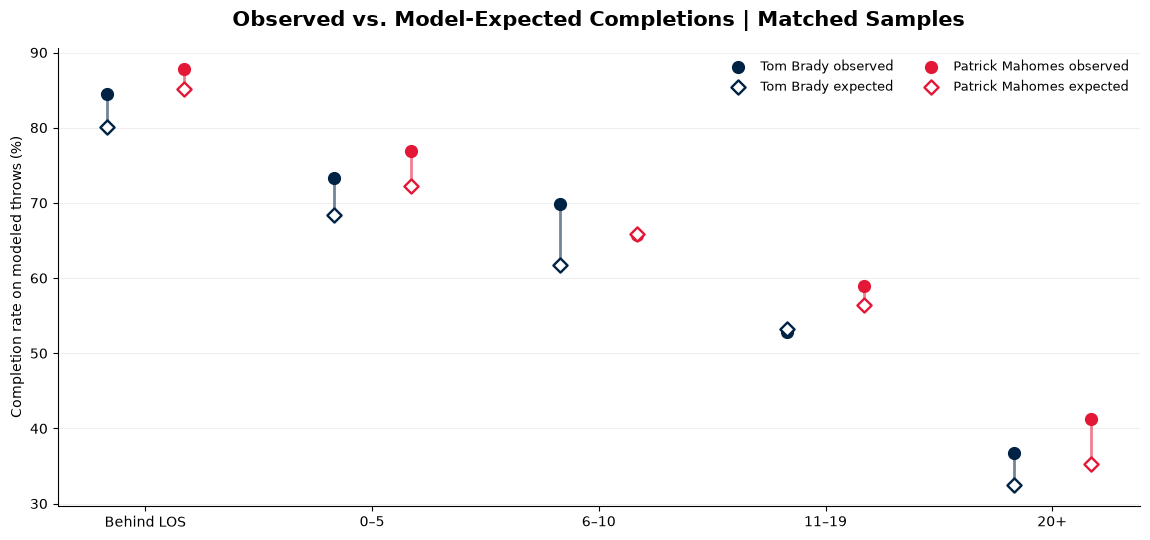

In [7]:
fig, ax = plt.subplots(figsize=(11.6, 5.5))
x = np.arange(len(ORDER))
for player, offset in (("Tom Brady", -.17), ("Patrick Mahomes", .17)):
    z = summary[summary.player_name.eq(player)].set_index("depth_zone").reindex(ORDER)
    actual = z.modeled_completion_pct.to_numpy(float)
    expected = z.expected_completion_pct.to_numpy(float)
    xpos = x+offset
    for xi, lo, hi in zip(xpos, expected, actual):
        ax.plot([xi,xi], [lo,hi], color=COLORS[player], alpha=.55, lw=2)
    ax.scatter(xpos, actual, marker="o", s=72, color=COLORS[player],
               label=f"{player} observed", zorder=3)
    ax.scatter(xpos, expected, marker="D", s=52, facecolors="white",
               edgecolors=COLORS[player], linewidths=1.7,
               label=f"{player} expected", zorder=3)
ax.set_xticks(x, ORDER)
ax.set_ylabel("Completion rate on modeled throws (%)")
ax.set_title("Observed vs. Model-Expected Completions | Matched Samples",
             fontsize=15, fontweight="bold", pad=16)
ax.legend(frameon=False, ncol=2, fontsize=9)
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "18_observed_vs_expected_completion_depth.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. How much does CPOE availability vary by zone?

The full study has **4,103** official pass attempts, **4,102** with charted depth, and **3,988** usable for CPOE. CPOE is available on ~98.6% of Brady attempts versus ~96.1% of Mahomes attempts. Missing predictions need not be random; do not interpret small CPOE differences as conclusive without checking coverage patterns.

In [8]:
missingness = (summary.assign(cp_missing=lambda d:d.attempts-d.modeled_attempts)
               [["player_name","depth_zone","attempts","modeled_attempts","cp_missing","cp_coverage_pct"]]
               .sort_values(["player_name","depth_zone"]))
display(missingness.round(2))

# Season-specific small samples should not dictate pooled conclusions.
season_view = seasons[["player_name", "season", "depth_zone", "attempts",
                       "modeled_attempts", "cpoe_pp", "qb_epa_per_attempt"]]
print("Small-sample (N<30) seasonal cells:")
display(season_view[season_view.modeled_attempts < 30]
        .sort_values(["player_name","season","depth_zone"]).round(2))

,player_name,depth_zone,attempts,modeled_attempts,cp_missing,cp_coverage_pct
1,Patrick Mahomes,0–5,723,688,35,95.16
3,Patrick Mahomes,11–19,420,395,25,94.05
4,Patrick Mahomes,20+,304,296,8,97.37
2,Patrick Mahomes,6–10,445,432,13,97.08
0,Patrick Mahomes,Behind LOS,417,410,7,98.32
6,Tom Brady,0–5,761,750,11,98.55
8,Tom Brady,11–19,299,297,2,99.33
9,Tom Brady,20+,202,199,3,98.51
7,Tom Brady,6–10,331,328,3,99.09
5,Tom Brady,Behind LOS,200,193,7,96.50


Small-sample (N<30) seasonal cells:


,player_name,season,depth_zone,attempts,modeled_attempts,cpoe_pp,qb_epa_per_attempt
31,Tom Brady,2008,0–5,5,5,-26.95,-0.36
33,Tom Brady,2008,11–19,2,2,-7.19,0.29
34,Tom Brady,2008,20+,1,1,77.33,1.49
32,Tom Brady,2008,6–10,1,1,27.31,0.43
30,Tom Brady,2008,Behind LOS,2,2,15.96,-0.33
43,Tom Brady,2010,11–19,16,16,-20.06,0.18
44,Tom Brady,2010,20+,13,13,0.64,0.32
42,Tom Brady,2010,6–10,20,19,1.24,0.47
40,Tom Brady,2010,Behind LOS,12,12,16.68,0.05


## 8. CPOE across seasons and depth zones

**Question:** Is Brady's advantage at **6–10 air yards** visible across several seasons, or driven only by 2007?

Each cell shows the season-specific **attempt-weighted** CPOE (percentage points) and the number of modeled throws (`n`). **Gray cells mean fewer than 30 modeled throws**, so their CPOE estimates are intentionally not color-encoded; this is a visualization threshold, not a validity rule. The color scale is clipped at ±15 pp **for display only**, while the labels preserve the computed values.

Brady 2008 (one study start) and 2010 (four study starts) are not comparable to a full season of Mahomes. Do not interpret the plotted rows as independently selected or equivalently long career eras.

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


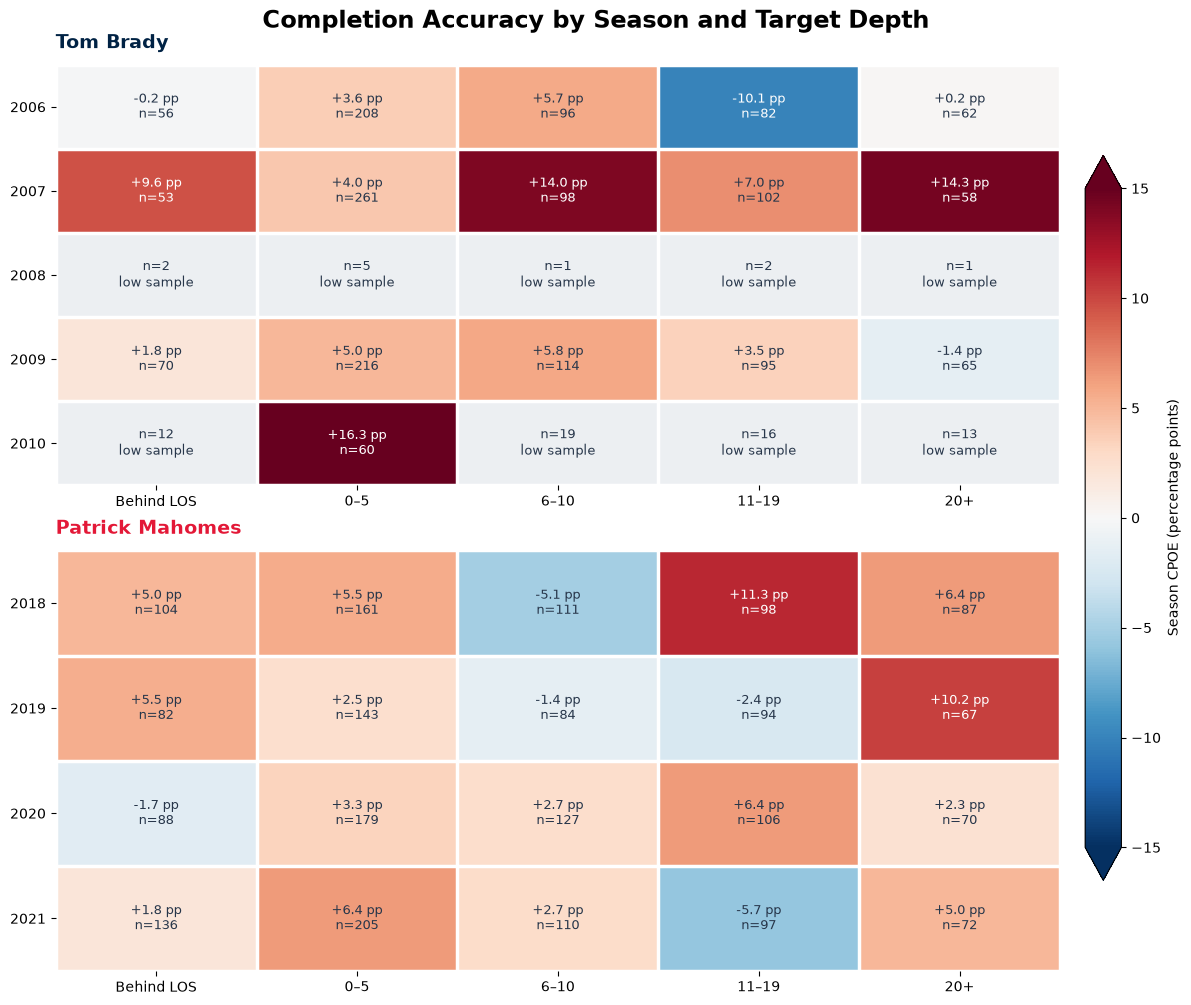

Brady 6–10 yard CPOE by study season:


,season,modeled_attempts,cpoe_pp,cp_coverage_pct
22,2006,96,5.74,98.97
27,2007,98,13.99,100.00
32,2008,1,27.31,100.00
37,2009,114,5.84,99.13
42,2010,19,1.24,95.00


In [9]:
from matplotlib.colors import TwoSlopeNorm

FIGURES.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(2, 1, figsize=(11.8, 9.7), constrained_layout=True)
color_norm = TwoSlopeNorm(vmin=-15, vcenter=0, vmax=15)
map_handle = None

for ax, player in zip(axes, PLAYERS):
    player_seasons = seasons[seasons.player_name.eq(player)]
    years = sorted(player_seasons.season.unique())
    data = player_seasons.set_index(["season", "depth_zone"])
    values = np.full((len(years), len(ORDER)), np.nan)

    for i, year in enumerate(years):
        for j, zone in enumerate(ORDER):
            if (year, zone) not in data.index:
                continue
            entry = data.loc[(year, zone)]
            n = int(entry["modeled_attempts"])
            value = float(entry["cpoe_pp"]) if n and pd.notna(entry["cpoe_pp"]) else np.nan
            if n >= 30 and np.isfinite(value):
                values[i, j] = value
            label = f"{value:+.1f} pp\nn={n}" if n >= 30 else f"n={n}\nlow sample"
            text_color = "white" if n >= 30 and abs(value) >= 9 else "#27364A"
            ax.text(j, i, label, ha="center", va="center", fontsize=9,
                    fontweight="medium", color=text_color)

    masked_values = np.ma.masked_invalid(values)
    cmap = plt.get_cmap("RdBu_r").copy()
    cmap.set_bad("#ECEFF2")
    map_handle = ax.imshow(masked_values, cmap=cmap, norm=color_norm, aspect="auto")
    ax.set_xticks(range(len(ORDER)), ORDER)
    ax.set_yticks(range(len(years)), [str(year) for year in years])
    ax.set_xticks(np.arange(-.5, len(ORDER), 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(years), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2.5)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_title(player, loc="left", fontsize=14, fontweight="bold",
                 color=COLORS[player], pad=12)
    ax.spines[:].set_visible(False)

fig.colorbar(map_handle, ax=axes, shrink=.8, pad=.025, extend="both",
             label="Season CPOE (percentage points)")
fig.suptitle("Completion Accuracy by Season and Target Depth", fontsize=17,
             fontweight="bold", y=1.02)
fig.savefig(FIGURES / "19_cpoe_by_season_and_depth.png", dpi=300, bbox_inches="tight")
plt.show()

print("Brady 6–10 yard CPOE by study season:")
display(seasons[(seasons.player_name == "Tom Brady") &
                (seasons.depth_zone == "6–10")]
        [["season", "modeled_attempts", "cpoe_pp", "cp_coverage_pct"]]
        .round(2).sort_values("season"))

## 9. Direct CPOE difference: Brady minus Mahomes

The prior plot shows **separate** intervals for each quarterback, but their overlap does *not* directly answer whether the two CPOEs differ.

We therefore bootstrap the contrast **Brady CPOE − Mahomes CPOE** at each depth. In each replication we independently sample **entire games with replacement within each quarterback's selected study period** and calculate a difference between **pooled, throw-weighted CPOEs**. This preserves the original difference in games (53 versus 62) and accounts for within-game clustering better than resampling individual throws.

**Interpretation:** positive values favor Brady and negative values favor Mahomes. The displayed 95% bootstrap percentile intervals are exploratory, without multiple-comparison adjustment across five depth zones. They describe uncertainty due to game-to-game variation *within the chosen career windows*, not uncertainty due to choosing different periods, model calibration, teammates, or the NFL era.

Direct CPOE differences (Brady − Mahomes):


,depth_zone,brady_games,mahomes_games,brady_modeled_throws,mahomes_modeled_throws,brady_cpoe_pp,mahomes_cpoe_pp,brady_minus_mahomes_pp,ci_low_pp,ci_high_pp,interval_excludes_zero
0,Behind LOS,53,62,193,410,4.42,2.59,1.83,-3.85,7.29,False
1,0–5,53,62,750,688,4.98,4.59,0.39,-4.34,5.00,False
2,6–10,53,62,328,432,8.04,-0.10,8.15,1.94,14.31,True
3,11–19,53,62,297,395,-0.39,2.55,-2.94,-10.66,5.05,False
4,20+,53,62,199,296,4.23,5.93,-1.70,-10.25,7.45,False


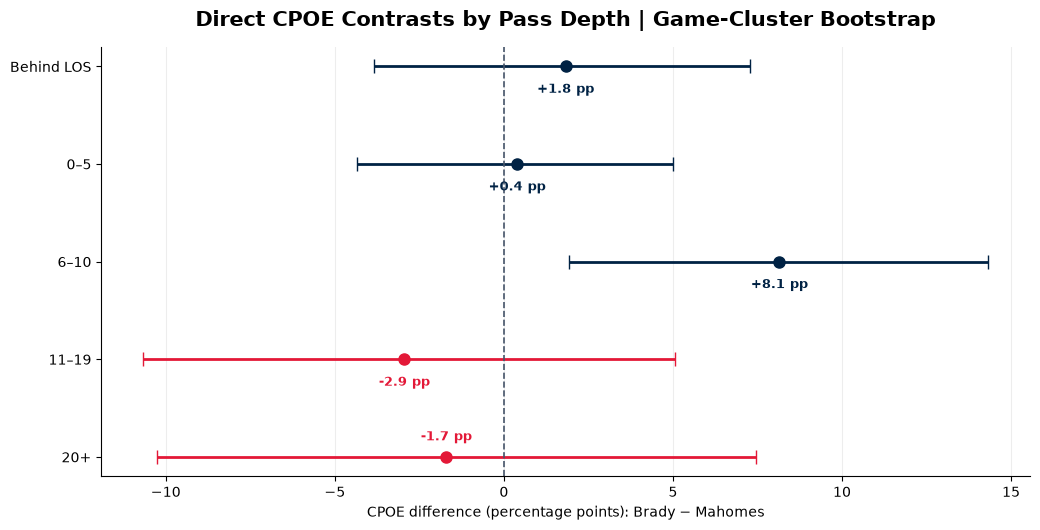

In [10]:
def game_vectors(frame, player, depth_zone, omit_seasons=()):
    """Return game-level CPOE sufficient statistics, including games with no throws in a zone."""
    cohort = frame[frame.player_name.eq(player)].copy()
    cohort = cohort[~cohort.season.isin(list(omit_seasons))]
    game_ids = (cohort[["game_id", "season"]].drop_duplicates()
                .sort_values("game_id"))
    selected = cohort[cohort.depth_zone.eq(depth_zone)][
        ["game_id", "modeled_attempts", "sum_cpoe_pp"]
    ]
    assert not selected.game_id.duplicated().any(), "Duplicate game-zone rows"
    merged = game_ids.merge(selected, on="game_id", how="left", validate="one_to_one")
    n = merged.modeled_attempts.fillna(0).to_numpy(dtype=float)
    s = merged.sum_cpoe_pp.fillna(0).to_numpy(dtype=float)
    assert len(n) > 0 and np.all(n >= 0) and np.isfinite(s).all()
    assert n.sum() > 0, f"No modeled throws in {player}, {depth_zone}"
    return n, s, len(game_ids)


def bootstrap_direct_difference(frame, zone, *, omit_brady_seasons=(),
                                repetitions=10000, seed=20261029):
    """Independently resample Brady and Mahomes games; calculate Brady minus Mahomes."""
    brady_n, brady_sum, brady_games = game_vectors(
        frame, "Tom Brady", zone, omit_brady_seasons
    )
    mahomes_n, mahomes_sum, mahomes_games = game_vectors(
        frame, "Patrick Mahomes", zone
    )
    brady_est = brady_sum.sum() / brady_n.sum()
    mahomes_est = mahomes_sum.sum() / mahomes_n.sum()
    rng = np.random.default_rng(seed)
    brady_draws = rng.integers(0, brady_games, size=(repetitions, brady_games))
    mahomes_draws = rng.integers(0, mahomes_games, size=(repetitions, mahomes_games))

    bn, bs = brady_n[brady_draws].sum(axis=1), brady_sum[brady_draws].sum(axis=1)
    mn, ms = mahomes_n[mahomes_draws].sum(axis=1), mahomes_sum[mahomes_draws].sum(axis=1)
    bboot = np.divide(bs, bn, out=np.full(repetitions, np.nan), where=bn > 0)
    mboot = np.divide(ms, mn, out=np.full(repetitions, np.nan), where=mn > 0)
    diffs = bboot - mboot
    valid = diffs[np.isfinite(diffs)]
    if len(valid) < repetitions * .99:
        raise AssertionError("Too many bootstrap draws have no modeled throws")
    low, high = np.quantile(valid, [.025, .975])
    return {
        "depth_zone": zone,
        "brady_games": brady_games,
        "mahomes_games": mahomes_games,
        "brady_modeled_throws": int(brady_n.sum()),
        "mahomes_modeled_throws": int(mahomes_n.sum()),
        "brady_cpoe_pp": brady_est,
        "mahomes_cpoe_pp": mahomes_est,
        "brady_minus_mahomes_pp": brady_est - mahomes_est,
        "ci_low_pp": low,
        "ci_high_pp": high,
        "interval_excludes_zero": bool(low > 0 or high < 0),
    }


contrasts = pd.DataFrame([
    bootstrap_direct_difference(games, zone, seed=20261029 + i)
    for i, zone in enumerate(ORDER)
])

# Reconcile bootstrap source summaries to the already-audited pooled CPOE table.
for _, r in contrasts.iterrows():
    for player, field in [("Tom Brady", "brady_cpoe_pp"),
                          ("Patrick Mahomes", "mahomes_cpoe_pp")]:
        expected = summary[(summary.player_name == player) &
                           (summary.depth_zone == r.depth_zone)].cpoe_pp.iloc[0]
        assert np.isclose(r[field], expected, atol=1e-8), (player, r.depth_zone)

print("Direct CPOE differences (Brady − Mahomes):")
display(contrasts.round(2))

fig, ax = plt.subplots(figsize=(10.5, 5.4))
for y, item in enumerate(contrasts.itertuples(index=False)):
    difference = item.brady_minus_mahomes_pp
    low, high = item.ci_low_pp, item.ci_high_pp
    color = COLORS["Tom Brady"] if difference >= 0 else COLORS["Patrick Mahomes"]
    ax.errorbar(difference, y,
                xerr=[[max(difference-low, 0)], [max(high-difference, 0)]],
                fmt="o", color=color, capsize=5, markersize=8, elinewidth=2)
    ax.annotate(f"{difference:+.1f} pp", (difference, y),
                xytext=(0, 12 if y == len(ORDER)-1 else -19), textcoords="offset points", ha="center",
                fontsize=9, fontweight="bold", color=color)
ax.axvline(0, color="#465469", linestyle="--", linewidth=1.2)
ax.set_yticks(range(len(ORDER)), ORDER)
ax.invert_yaxis()
ax.set_xlabel("CPOE difference (percentage points): Brady − Mahomes")
ax.set_title("Direct CPOE Contrasts by Pass Depth | Game-Cluster Bootstrap",
             fontsize=15, fontweight="bold", pad=15)
ax.grid(axis="x", alpha=.22)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "20_cpoe_direct_differences_bootstrap.png",
            dpi=300, bbox_inches="tight")
plt.show()

OUT_REPORTS = Path("../reports")
OUT_REPORTS.mkdir(parents=True, exist_ok=True)
contrasts.to_csv(OUT_REPORTS / "pass_depth_cpoe_direct_contrasts.csv", index=False)

### Sensitivity: does the 6–10 yard difference survive excluding Brady's 2007 season?

Removing 2007 changes the **population of studied Brady games**, rather than correcting a known measurement error. It provides a *sensitivity analysis*, not an unbiased estimate of what Brady would have done without that season.

The table below reports the pooled 6–10 yard CPOE contrast for the full sample, after **excluding Brady 2007**, and after removing each Brady study season individually. Mahomes's original 2018–2021 games are kept fixed in every comparison. All reported intervals are game-cluster bootstrap percentile intervals, recomputed for each altered sample.

In [11]:
checks = [("Full study windows", ())] + [
    (f"Exclude Brady {year}", (year,))
    for year in sorted(seasons[seasons.player_name.eq("Tom Brady")].season.unique())
]
leave_one_out = pd.DataFrame([
    {"comparison": label, **bootstrap_direct_difference(
        games, "6–10", omit_brady_seasons=omit, seed=20261030 + i
    )}
    for i, (label, omit) in enumerate(checks)
])

print("6–10 yard CPOE sensitivity (Mahomes period held fixed):")
display(leave_one_out[["comparison", "brady_games", "brady_modeled_throws",
                       "brady_cpoe_pp", "mahomes_cpoe_pp", "brady_minus_mahomes_pp",
                       "ci_low_pp", "ci_high_pp", "interval_excludes_zero"]].round(2))

# Exact pooled CPOE check using season-level sufficient statistics (no bootstrap).
season_sufficient = seasons[(seasons.player_name == "Tom Brady") &
                          (seasons.depth_zone == "6–10")].copy()
without_2007 = season_sufficient[season_sufficient.season != 2007]
by_season_cpoe = (without_2007.sum_cpoe_pp.sum() /
                  without_2007.modeled_attempts.sum())
measured_from_games = leave_one_out.loc[
    leave_one_out.comparison == "Exclude Brady 2007", "brady_cpoe_pp"
].iloc[0]
assert np.isclose(by_season_cpoe, measured_from_games, atol=1e-8)

leave_one_out.to_csv(OUT_REPORTS / "pass_depth_cpoe_6_10_leave_one_season_out.csv",
                     index=False)

6–10 yard CPOE sensitivity (Mahomes period held fixed):


,comparison,brady_games,brady_modeled_throws,brady_cpoe_pp,mahomes_cpoe_pp,brady_minus_mahomes_pp,ci_low_pp,ci_high_pp,interval_excludes_zero
0,Full study windows,53,328,8.04,-0.10,8.15,2.02,14.33,True
1,Exclude Brady 2006,37,232,9.00,-0.10,9.10,2.32,15.81,True
2,Exclude Brady 2007,37,230,5.51,-0.10,5.61,-1.81,12.80,False
3,Exclude Brady 2008,52,327,7.99,-0.10,8.09,1.85,14.18,True
4,Exclude Brady 2009,37,214,9.22,-0.10,9.32,2.54,15.99,True
5,Exclude Brady 2010,49,309,8.46,-0.10,8.57,2.28,14.69,True


## 10. Key questions and interpretation checklist

Before writing conclusions, record numerical answers to:

1. Where is each quarterback's **attempt share** concentrated? Do they target different depths?
2. Are the **completion rates** different because attempts are more/less difficult, or does **CPOE** also differ?
3. Which depths contribute the most **QB EPA per throw**, and does this align with accuracy?
4. How many **modeled attempts** underlie each CPOE estimate, especially deep throws?
5. Do the **direct game-cluster bootstrap intervals for Brady − Mahomes** include zero, and is there a stable 6–10 yard advantage after excluding Brady 2007?

### Methodological boundaries

- CPOE is a **model-dependent descriptive residual**, not an isolation of QB talent or improvisation. Receiver skill, coverage, pressure, and era-specific model calibration may matter.
- Passing EPA by depth excludes sacks/scrambles, so it is **not** a decomposition of total quarterback dropback EPA from notebook 03.
- Brady has 53 selected starts and Mahomes 62; reported pooled metrics are **attempt-weighted**, not season-weighted.
- Brady 2008 has only 11 pass attempts: high single-game CPOE by zone is extremely unstable; Brady 2010 includes only four selected starts.
- The sample was chosen based on CPOE coverage and roster-context research questions, not a validated estimate of either QB's objectively best peak.
- One Mahomes 2020 throw lacks air yards; other throws lack `cp`. No values are invented for either.

**Follow-up research:** Check season/era calibration of completion probability and assess whether CPOE differences persist under alternative period definitions and more targeted opponent/context controls.

## Final Findings & Limitations

### 1. Passing Depth Distribution

Tom Brady and Patrick Mahomes displayed distinct passing-depth distributions during the selected study periods.

Brady concentrated a larger share of his attempts between 0 and 5 air yards, whereas Mahomes attempted a greater proportion of passes behind the line of scrimmage and at depths of 20 or more yards.

These differences describe offensive passing profiles rather than individual quarterback preferences alone, as play-calling, personnel, and defensive strategies may influence target selection.

### 2. Completion Efficiency and Offensive Value

Observed completion rates declined with increasing target depth for both quarterbacks.

Brady demonstrated stronger completion efficiency in the 6–10-yard range, while Mahomes generally produced higher observed completion rates at deeper target depths.

The EPA-per-attempt analysis revealed additional differences:

- Brady generated more EPA per attempt between 6 and 10 yards.
- Mahomes generated more EPA per attempt in the 11–19 and 20+ yard ranges.
- Higher EPA per attempt did not necessarily correspond to proportionally higher CPOE.

These findings demonstrate that completion accuracy and offensive value capture different aspects of passing performance.

### 3. Completion Percentage Over Expected

CPOE provided a more contextualized measure of completion accuracy by comparing observed completions with model-predicted completion probabilities.

The most notable finding occurred in the 6–10-yard range:

| Metric | Tom Brady | Patrick Mahomes |
|---|---:|---:|
| Modeled attempts | 328 | 432 |
| Aggregate CPOE | +8.04 pp | −0.10 pp |

Brady exceeded the model's completion expectations by approximately eight percentage points, while Mahomes performed close to the expected completion rate.

The observed difference was approximately **+8.15 percentage points in Brady's favor**.

### 4. Season-Level Consistency

Brady recorded positive 6–10-yard CPOE in each of the three seasons with substantial sample sizes:

- 2006: +5.7 pp
- 2007: +14.0 pp
- 2009: +5.8 pp

Mahomes recorded negative values in 2018 and 2019, followed by modestly positive values in 2020 and 2021.

This suggests that Brady's observed advantage was not confined to a single season, although 2007 contributed substantially to its magnitude.

### 5. Bootstrap Uncertainty

A game-cluster bootstrap with 10,000 resamples was used to estimate uncertainty in the direct CPOE differences between the quarterbacks.

For the 6–10-yard range:

**Brady − Mahomes: +8.15 pp**

**Exploratory 95% bootstrap confidence interval: [+2.02, +14.33] pp**

This interval excludes zero, providing exploratory statistical evidence of a positive difference in the selected samples.

The other four depth zones had confidence intervals that included zero. Therefore, the analysis did not establish clear between-quarterback CPOE differences in those zones.

These intervals are not adjusted for multiple depth-zone comparisons.

### 6. Sensitivity to Brady's 2007 Season

To investigate whether the 6–10-yard result depended primarily on Brady's exceptional 2007 season, a leave-one-season-out analysis was performed.

Excluding 2007 reduced Brady's CPOE from +8.04 to +5.51 percentage points.

The direct difference relative to Mahomes decreased to:

**Brady − Mahomes: +5.61 pp**

**95% bootstrap confidence interval: [−1.81, +12.80] pp**

The positive point estimate persisted, but the confidence interval included zero.

Consequently, the observed advantage does not disappear when 2007 is excluded, although the statistical evidence becomes less conclusive.

### 7. Research Limitations

Several limitations affect the interpretation of these findings:

- **Historical comparability:** The study compares different NFL periods, and the completion-probability model may not be equally calibrated across eras.
- **Team context:** Receivers, offensive schemes, pass protection, opponents, and defensive coverage may influence the observed results.
- **Unequal sampling:** Brady contributed 53 starts and Mahomes 62 starts within the selected study windows.
- **Missing model predictions:** CPOE coverage was approximately 98.6% for Brady and 96.1% for Mahomes. Missing predictions may introduce selection bias.
- **Statistical uncertainty:** Game-cluster resampling accounts for within-game dependence, but does not fully account for season-level differences or all sources of historical variation.
- **Multiple comparisons:** The five depth-zone contrasts were examined exploratorily without family-wise error adjustment.
- **Metric interpretation:** CPOE measures performance relative to modeled completion difficulty, not isolated quarterback talent or improvisational skill.

### 8. Final Conclusion

The pass-depth analysis reveals meaningful differences in how Brady and Mahomes generated passing efficiency.

Brady demonstrated particularly strong performance between 6 and 10 air yards, combining higher observed completion efficiency, greater EPA per attempt, and substantially positive CPOE.

Mahomes generated greater observed offensive value at deeper target depths and maintained positive deep-passing CPOE across all four examined seasons.

The direct bootstrap comparison identified the 6–10-yard range as the clearest observed advantage for Brady. However, excluding his exceptional 2007 season reduced the estimated difference and widened its uncertainty sufficiently to include zero.

**The findings support distinct passing-efficiency profiles rather than establishing that either quarterback possesses universally superior passing accuracy.**

Further research could investigate model calibration across eras, receiver and defensive context, and the stability of CPOE differences under alternative historical samples.